# Assignment 1

In [1]:
import json
import os
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup

os.makedirs("images", exist_ok=True)

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [2]:
def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")
    for tag in soup(["script", "style", "noscript", "template", "svg", "iframe"]):
        tag.decompose()
    lines = (line.strip() for line in soup.get_text(separator="\n").splitlines())
    return "\n".join(line for line in lines if line)

print(parse_web_page('https://fmi.chnu.edu.ua/')[:255])
print(parse_web_page('https://en.wikipedia.org/wiki/Web_scraping')[:255])

Головна - Факультет математики та інформатики
Перейти до основного вмісту
clg-math@chnu.edu.ua
58012, Україна, м. Чернівці, вул. Університетська, 28
Новини
Всі
Загальні
Оголошення
Події
Студенту
Викладачу
Вітання
Діяльність
Наукова
Конференції
Семінари
Ас


Web scraping - Wikipedia
Jump to content
Main menu
Main menu
move to sidebar
hide
Navigation
Main page
Contents
Current events
Random article
About Wikipedia
Contact us
Contribute
Help
Learn to edit
Community portal
Recent changes
Upload file
Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [3]:
def parse_api(api_url):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """
    response = requests.get(api_url, timeout=30)
    response.raise_for_status()
    with open("result.json", "w", encoding="utf-8") as f:
        json.dump(response.json(), f, ensure_ascii=False, indent=4)

parse_api('https://api.open-meteo.com/v1/forecast?latitude=48.29&longitude=25.94&daily=temperature_2m_max,temperature_2m_min,precipitation_sum&timezone=Europe%2FKyiv')

with open("result.json", encoding="utf-8") as f:
    print(json.dumps(json.load(f), indent=4)[:500])

{
    "latitude": 48.318634,
    "longitude": 25.971066,
    "generationtime_ms": 0.10251998901367188,
    "utc_offset_seconds": 10800,
    "timezone": "Europe/Kyiv",
    "timezone_abbreviation": "GMT+3",
    "elevation": 235.0,
    "daily_units": {
        "time": "iso8601",
        "temperature_2m_max": "\u00b0C",
        "temperature_2m_min": "\u00b0C",
        "precipitation_sum": "mm"
    },
    "daily": {
        "time": [
            "2026-10-23",
            "2026-10-24",
            "20


## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [4]:
def to_date(value):
    return datetime.strptime(value.strip(), "%Y-%m-%d").date()


def parse_json(date):
    """
    Parse the data from weather.json file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    with open("resources/weather.json", encoding="utf-8") as f:
        data = json.load(f)
    target = to_date(date)
    for day in data["daily"]:
        if to_date(day["date"]) == target:
            return list(day.values())
    return []

target_date = '2024-8-19'
print(parse_json(target_date))

['2024-08-19', 30.0, 21.0, 5.0, 10.0, 70, 'Light rain']


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [5]:
def load_weather_csv():
    df = pd.read_csv("resources/weather.csv")
    df.columns = df.columns.str.strip()
    df["CET"] = pd.to_datetime(df["CET"], format="%Y-%m-%d")
    return df


def parse_csv(date):
    """
    Parse the data from weather.csv file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """
    df = load_weather_csv()
    rows = df[df["CET"].dt.date == to_date(date)]
    if rows.empty:
        return []
    row = rows.iloc[0].copy()
    row["CET"] = row["CET"].strftime("%Y-%m-%d")
    return [None if pd.isna(value) else getattr(value, "item", lambda: value)() for value in row.tolist()]

target_date = '1997-5-22'
print(parse_csv(target_date))

['1997-05-22', 25.0, 18.0, 10.0, 11.0, 8.0, 6.0, 88.0, 54.0, 34.0, 1017, 1015, 1012, 10.0, 10.0, 10.0, 11, 3, None, 0.0, 3.0, None, 277]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

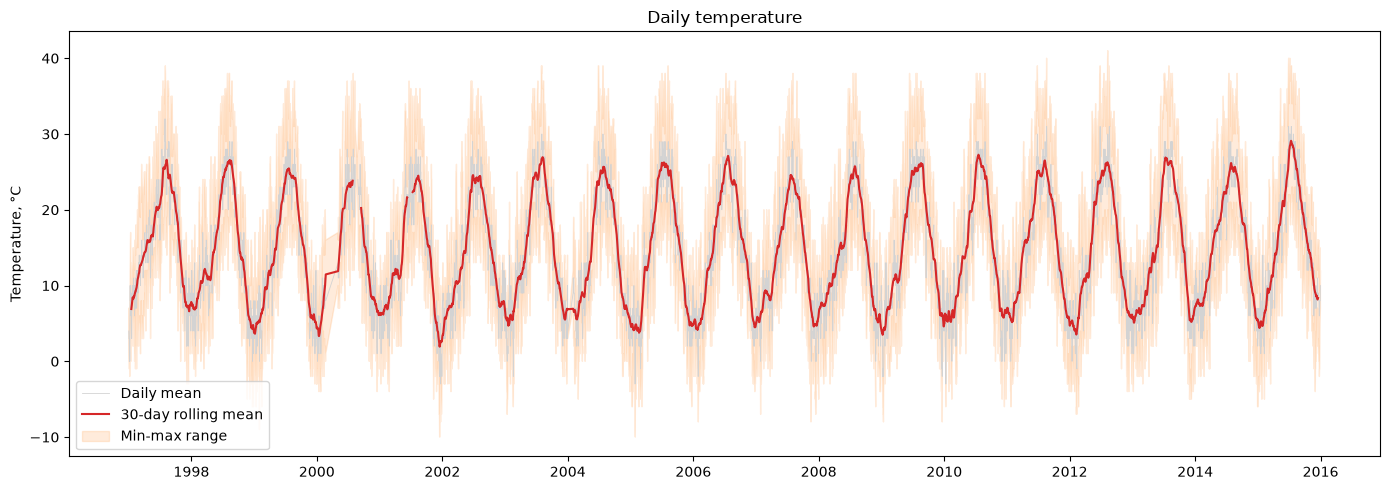

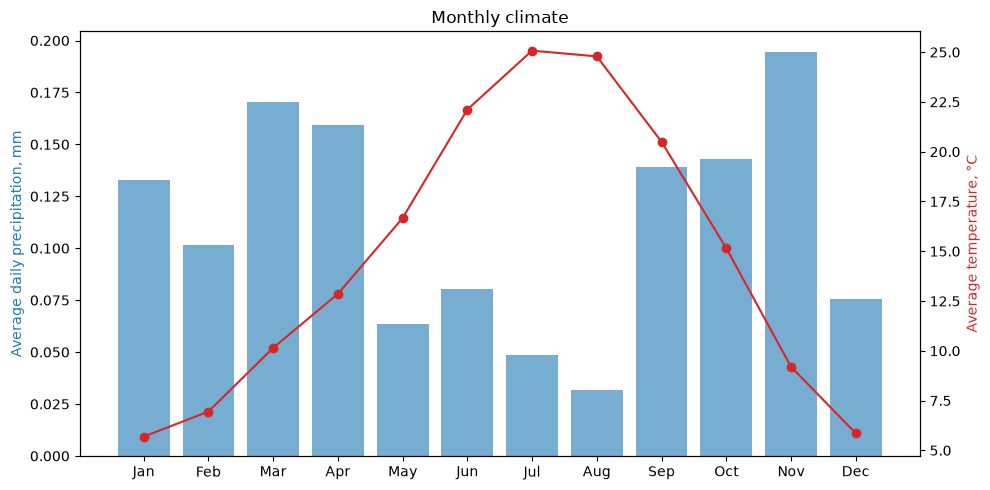

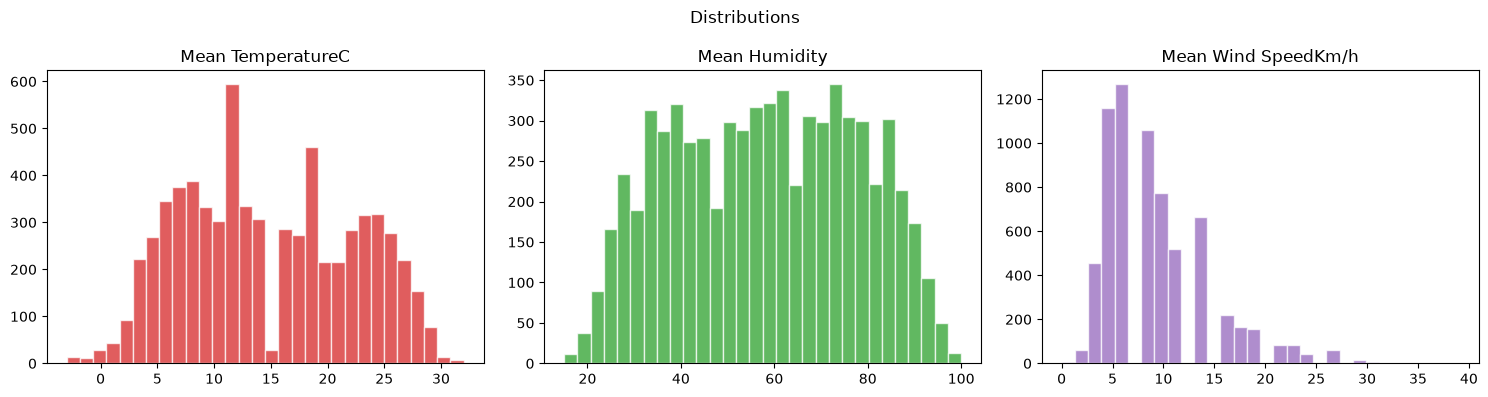

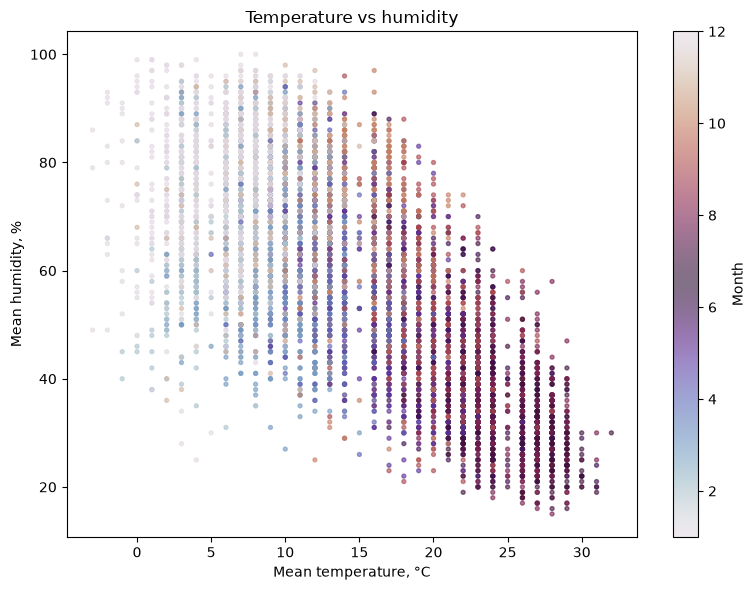

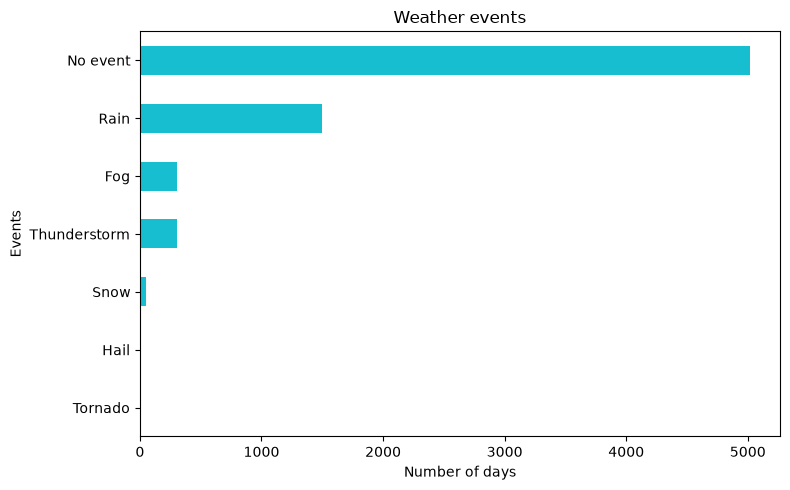

In [6]:
def visualize_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib. Use more then one visualization.
    Save the results in the repository.

    Args:
        None: None.

    Returns:
        None: None.
    """
    df = load_weather_csv().set_index("CET").sort_index()

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(df.index, df["Mean TemperatureC"], color="lightgray", linewidth=0.6, label="Daily mean")
    ax.plot(df.index, df["Mean TemperatureC"].rolling(30, center=True).mean(), color="tab:red", label="30-day rolling mean")
    ax.fill_between(df.index, df["Min TemperatureC"], df["Max TemperatureC"], color="tab:orange", alpha=0.15, label="Min-max range")
    ax.set_title("Daily temperature")
    ax.set_ylabel("Temperature, °C")
    ax.legend()
    fig.tight_layout()
    fig.savefig("images/weather_temperature_timeline.png", dpi=120)
    plt.show()

    monthly = df.groupby(df.index.month).agg(
        temperature=("Mean TemperatureC", "mean"),
        precipitation=("Precipitationmm", "mean"),
    )
    month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    fig, ax1 = plt.subplots(figsize=(10, 5))
    ax1.bar(month_names, monthly["precipitation"], color="tab:blue", alpha=0.6, label="Precipitation")
    ax1.set_ylabel("Average daily precipitation, mm", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(month_names, monthly["temperature"], color="tab:red", marker="o", label="Temperature")
    ax2.set_ylabel("Average temperature, °C", color="tab:red")
    ax1.set_title("Monthly climate")
    fig.tight_layout()
    fig.savefig("images/weather_monthly_climate.png", dpi=120)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, column, color in zip(
        axes,
        ["Mean TemperatureC", "Mean Humidity", "Mean Wind SpeedKm/h"],
        ["tab:red", "tab:green", "tab:purple"],
    ):
        ax.hist(df[column].dropna(), bins=30, color=color, alpha=0.75, edgecolor="white")
        ax.set_title(column)
    fig.suptitle("Distributions")
    fig.tight_layout()
    fig.savefig("images/weather_distributions.png", dpi=120)
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 6))
    points = ax.scatter(df["Mean TemperatureC"], df["Mean Humidity"], c=df.index.month, cmap="twilight", s=8, alpha=0.6)
    fig.colorbar(points, ax=ax, label="Month")
    ax.set_xlabel("Mean temperature, °C")
    ax.set_ylabel("Mean humidity, %")
    ax.set_title("Temperature vs humidity")
    fig.tight_layout()
    fig.savefig("images/weather_temp_vs_humidity.png", dpi=120)
    plt.show()

    events = df["Events"].fillna("No event").str.split("-").explode().value_counts()
    fig, ax = plt.subplots(figsize=(8, 5))
    events.sort_values().plot.barh(ax=ax, color="tab:cyan")
    ax.set_xlabel("Number of days")
    ax.set_title("Weather events")
    fig.tight_layout()
    fig.savefig("images/weather_events.png", dpi=120)
    plt.show()

visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

(6497, 13)
type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


knn       0.8379
mean      1.0051
median    1.0304
mode      1.1214
Name: normalized RMSE, dtype: float64
best numeric imputation: knn
fixed acidity            robust
volatile acidity         robust
citric acid              robust
residual sugar           minmax
chlorides                robust
free sulfur dioxide      minmax
total sulfur dioxide    z-score
density                  minmax
pH                      z-score
sulphates                robust
alcohol                  minmax
quality                  robust


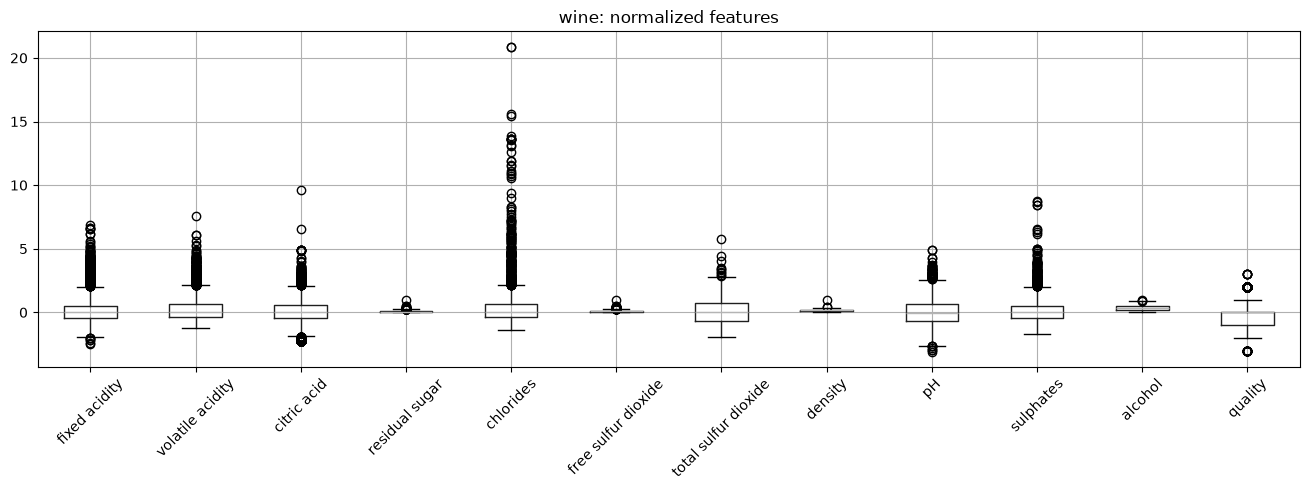

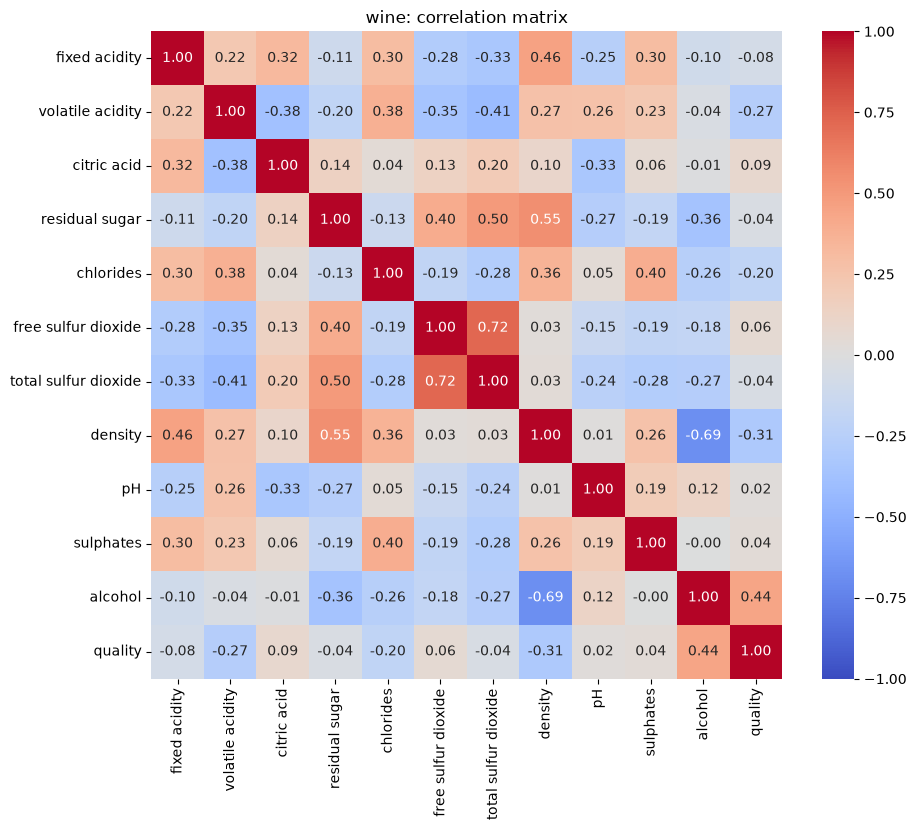

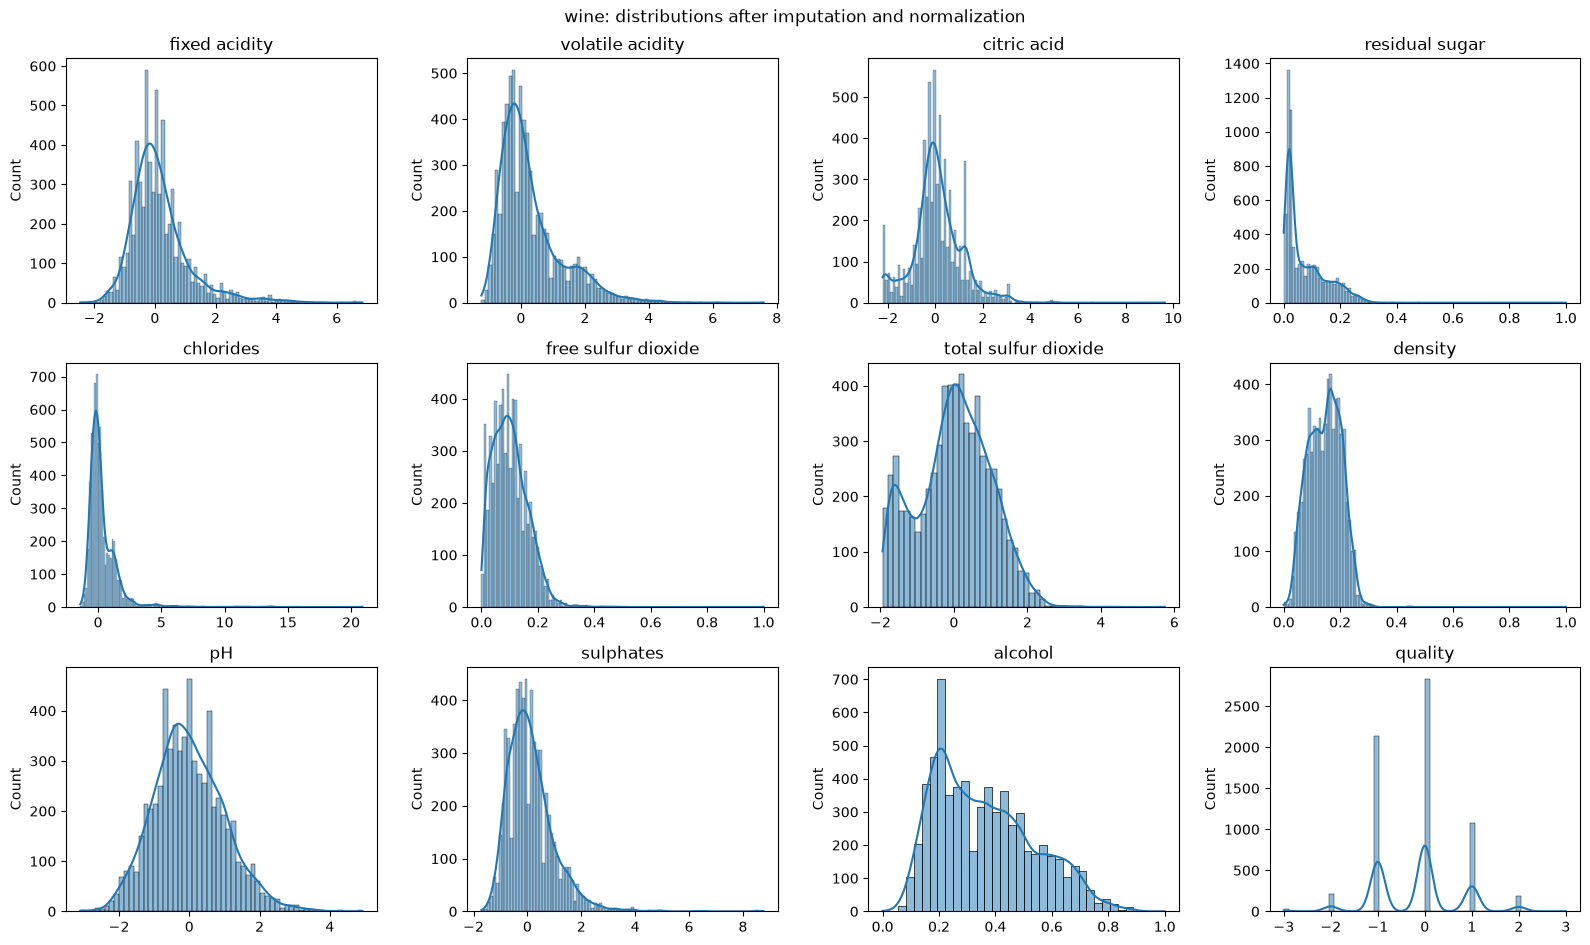

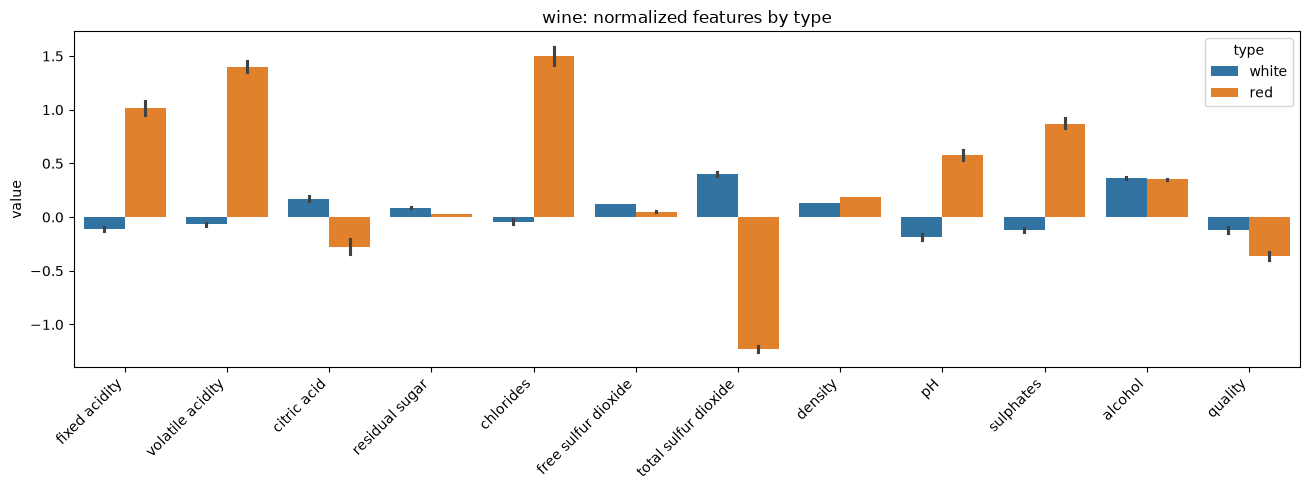

In [7]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df


IMPUTERS = {
    "mean": lambda: SimpleImputer(strategy="mean"),
    "median": lambda: SimpleImputer(strategy="median"),
    "mode": lambda: SimpleImputer(strategy="most_frequent"),
    "knn": lambda: KNNImputer(n_neighbors=5),
}


def numeric_columns(df):
    return df.select_dtypes(include="number").columns


def impute_numeric(df, method):
    imputed = df.copy()
    columns = numeric_columns(df)
    imputed[columns] = IMPUTERS[method]().fit_transform(df[columns])
    return imputed


def evaluate_imputers(df, share=0.05, seed=42):
    columns = numeric_columns(df)
    complete = df[columns].dropna().reset_index(drop=True)
    rng = np.random.default_rng(seed)
    mask = rng.random(complete.shape) < share
    damaged = complete.mask(mask)
    scale = complete.std().to_numpy()
    scores = {}
    for method in IMPUTERS:
        restored = IMPUTERS[method]().fit_transform(damaged)
        errors = ((restored - complete.to_numpy()) / scale) ** 2
        scores[method] = float(np.sqrt(errors[mask].mean()))
    return pd.Series(scores, name="normalized RMSE").sort_values()


def impute_data(df):
    """
    Parse the data from file and impute missing values using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with imputed values.
    """
    imputed = df.copy()
    if df[numeric_columns(df)].isna().any().any():
        scores = evaluate_imputers(df)
        print(scores.round(4))
        print(f"best numeric imputation: {scores.index[0]}")
        imputed = impute_numeric(df, scores.index[0])
    for column in imputed.select_dtypes(exclude="number").columns:
        imputed[column] = imputed[column].fillna(imputed[column].mode().iloc[0])
    return imputed


def choose_scaler(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).mean()
    if outliers > 0.02:
        return "robust", RobustScaler()
    if abs(series.skew()) < 0.5:
        return "z-score", StandardScaler()
    return "minmax", MinMaxScaler()


def normalize_data(df):
    """
    Normalize the data using your preferred method.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with normalized values.
    """
    normalized = df.copy()
    chosen = {}
    for column in numeric_columns(df):
        name, scaler = choose_scaler(df[column])
        normalized[column] = scaler.fit_transform(df[[column]]).ravel()
        chosen[column] = name
    print(pd.Series(chosen, name="scaler").to_string())
    return normalized


def visualize_data(df, name="wine"):
    """
    Visualize the data using Matplotlib. Use more then one visualization.
    Save the results in the repository.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        None: None.
    """
    numeric = df[numeric_columns(df)]
    categorical = df.select_dtypes(exclude="number").columns

    fig, ax = plt.subplots(figsize=(max(8, numeric.shape[1] * 1.1), 5))
    numeric.boxplot(ax=ax, rot=45)
    ax.set_title(f"{name}: normalized features")
    fig.tight_layout()
    fig.savefig(f"images/{name}_boxplots.png", dpi=120)
    plt.show()

    fig, ax = plt.subplots(figsize=(max(6, numeric.shape[1] * 0.8), max(5, numeric.shape[1] * 0.7)))
    sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{name}: correlation matrix")
    fig.tight_layout()
    fig.savefig(f"images/{name}_correlation.png", dpi=120)
    plt.show()

    columns = list(numeric.columns)
    cols = min(4, len(columns))
    rows = int(np.ceil(len(columns) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
    for ax, column in zip(axes.flat, columns):
        sns.histplot(numeric[column], kde=True, ax=ax, color="tab:blue")
        ax.set_title(column)
        ax.set_xlabel("")
    for ax in axes.flat[len(columns):]:
        ax.remove()
    fig.suptitle(f"{name}: distributions after imputation and normalization")
    fig.tight_layout()
    fig.savefig(f"images/{name}_distributions.png", dpi=120)
    plt.show()

    if len(categorical):
        category = categorical[0]
        fig, ax = plt.subplots(figsize=(max(8, len(columns) * 1.1), 5))
        sns.barplot(data=df.melt(id_vars=category, value_vars=columns), x="variable", y="value", hue=category, ax=ax)
        ax.set_title(f"{name}: normalized features by {category}")
        ax.set_xlabel("")
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        fig.tight_layout()
        fig.savefig(f"images/{name}_by_{category.replace('/', '_').replace(' ', '_')}.png", dpi=120)
        plt.show()

df = load_dataset('ilayaraja07/data-cleaning-feature-imputation', 'Wine_Quality.csv')
raw_wine = df.copy()
print(df.shape)
print(df.isna().sum())
df = impute_data(df)
df = normalize_data(df)
visualize_data(df, "wine")

### Comparison of imputation techniques

method              knn   mean  median   mode
column                                       
chlorides         0.053  0.056   0.047  0.044
citric acid       0.217  0.319   0.310  0.300
fixed acidity     7.274  7.217   7.000  6.800
pH                3.239  3.218   3.210  3.160
residual sugar    9.920  5.444   3.000  2.000
sulphates         0.624  0.531   0.510  0.500
volatile acidity  0.298  0.340   0.290  0.280


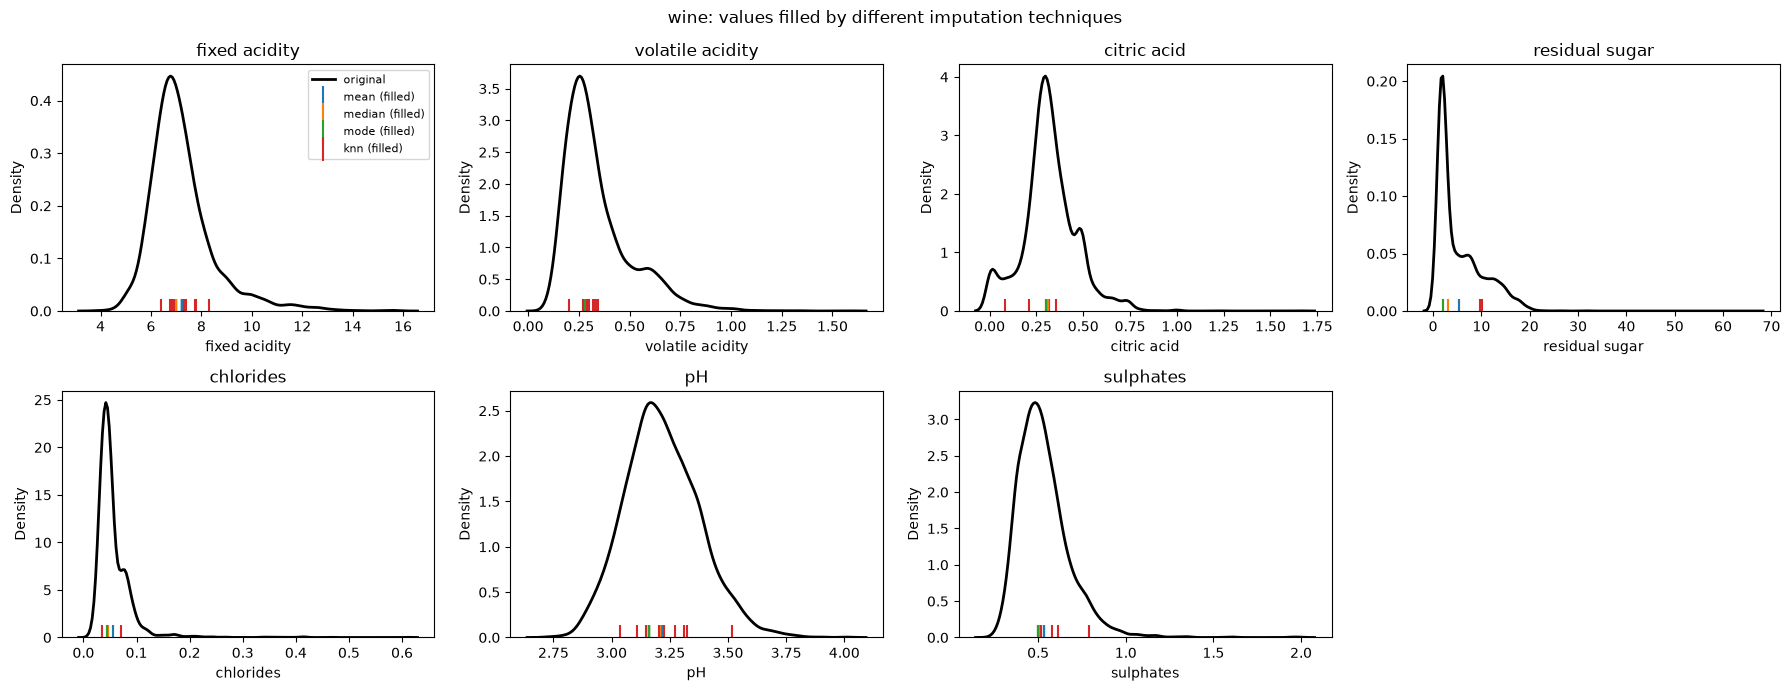

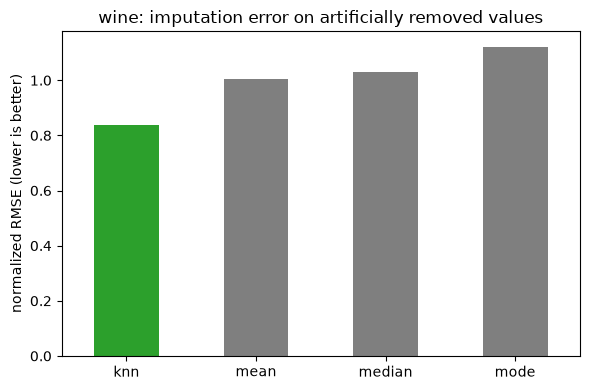

In [8]:
def compare_imputations(raw_df, name):
    columns = [column for column in numeric_columns(raw_df) if raw_df[column].isna().any()]
    variants = {method: impute_numeric(raw_df, method) for method in IMPUTERS}

    rows = []
    for method, variant in variants.items():
        for column in columns:
            filled = variant.loc[raw_df[column].isna(), column]
            rows.append({"method": method, "column": column, "mean of filled": filled.mean(), "std of filled": filled.std()})
    print(pd.DataFrame(rows).pivot(index="column", columns="method", values="mean of filled").round(3))

    scores = evaluate_imputers(raw_df)
    cols = min(4, len(columns))
    rows_count = int(np.ceil(len(columns) / cols))
    fig, axes = plt.subplots(rows_count, cols, figsize=(4.5 * cols, 3.5 * rows_count), squeeze=False)
    for ax, column in zip(axes.flat, columns):
        sns.kdeplot(raw_df[column].dropna(), ax=ax, label="original", color="black", linewidth=2)
        for method, variant in variants.items():
            ax.scatter(
                variant.loc[raw_df[column].isna(), column],
                np.zeros(raw_df[column].isna().sum()),
                marker="|",
                s=300,
                label=f"{method} (filled)",
            )
        ax.set_title(column)
    for ax in axes.flat[len(columns):]:
        ax.remove()
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"{name}: values filled by different imputation techniques")
    fig.tight_layout()
    fig.savefig(f"images/{name}_imputation_comparison.png", dpi=120)
    plt.show()

    fig, ax = plt.subplots(figsize=(6, 4))
    scores.plot.bar(ax=ax, color=["tab:green"] + ["tab:gray"] * (len(scores) - 1))
    ax.set_ylabel("normalized RMSE (lower is better)")
    ax.set_title(f"{name}: imputation error on artificially removed values")
    plt.setp(ax.get_xticklabels(), rotation=0)
    fig.tight_layout()
    fig.savefig(f"images/{name}_imputation_rmse.png", dpi=120)
    plt.show()

compare_imputations(raw_wine, "wine")

### Second dataset: students performance with missing categorical values

gender                          0
race/ethnicity                 11
parental level of education    21
lunch                          12
test preparation course         4
math score                      0
reading score                   0
writing score                   0
dtype: int64
0
math score       z-score
reading score    z-score
writing score    z-score


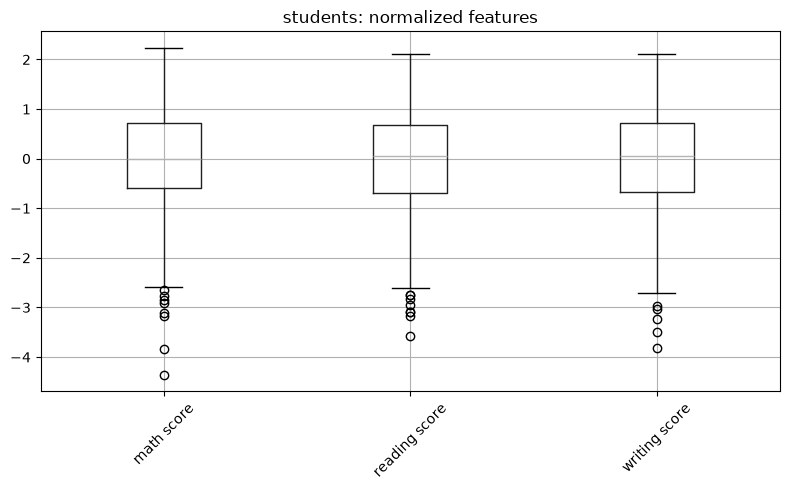

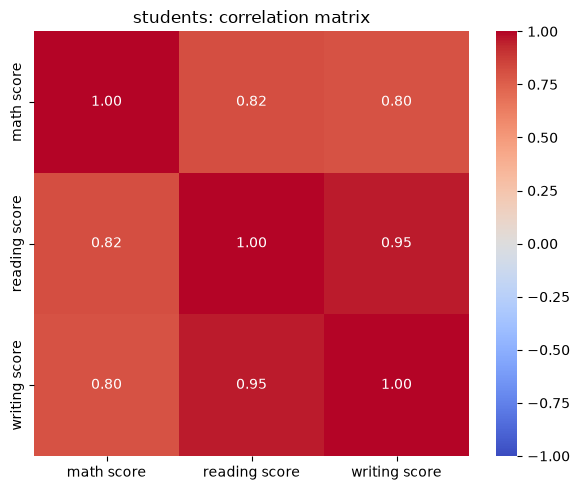

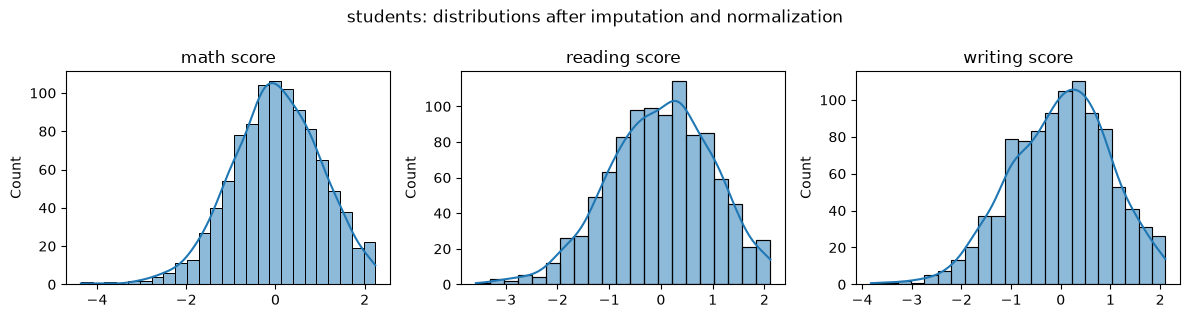

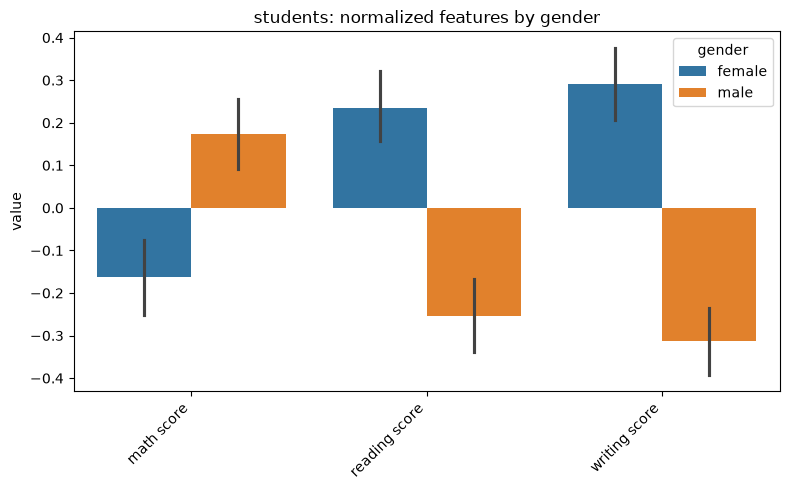

In [9]:
df = load_dataset('ilayaraja07/data-cleaning-feature-imputation', 'Students_Performance_mv.csv')
print(df.isna().sum())
df = impute_data(df)
print(df.isna().sum().sum())
df = normalize_data(df)
visualize_data(df, "students")